In [1]:
# Step 1: Import Required Libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.style.use('default')
plt.rcParams['figure.figsize'] = (9, 5)
print("Libraries successfully imported!")

Libraries successfully imported!


In [2]:
# Step 2: Load the Dataset
potential_paths = [
    "Diabetes_prediction.csv",
    "../Diabetes_prediction.csv",
    "../datasets/Diabetes_prediction.csv",
    "datasets/Diabetes_prediction.csv"
]

data_path = None
for p in potential_paths:
    if os.path.exists(p):
        data_path = p
        break

if data_path is None:
    raise FileNotFoundError("Diabetes_prediction.csv not found!")

df = pd.read_csv(data_path)
print(f"Loaded dataset from: {data_path}")
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Loaded dataset from: Diabetes_prediction.csv
Dataset Shape: 1000 rows, 9 columns


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Diagnosis
0,2,115.863387,56.410731,24.336736,94.385783,26.455940,0.272682,20.100494,0
1,2,92.490122,70.615520,23.443591,138.652426,23.910167,0.665160,44.912281,0
2,1,88.141469,63.262618,23.404364,149.358082,21.948250,0.676022,48.247873,1
3,2,108.453101,67.793632,20.751580,108.751638,24.209304,0.289636,42.749868,0
4,1,127.849443,94.725685,22.603078,25.269987,32.997477,0.601315,32.797789,0


In [3]:
# Step 3: Verify Missing Values and Target Statistics
print("Missing Values Count:")
print(df.isnull().sum())

print("\nGlucose Summary Statistics:")
print(df['Glucose'].describe())

Missing Values Count:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Diagnosis                   0
dtype: int64

Glucose Summary Statistics:
count    1000.000000
mean       99.440607
std        19.470730
min        30.571402
25%        86.145927
50%        99.458362
75%       113.264556
max       161.238939
Name: Glucose, dtype: float64


In [4]:
# Step 4: Simple Linear Regression Feature Matrix & Train-Test Split
X_simple = df[['Insulin']]
y_simple = df['Glucose']

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_simple, y_simple, test_size=0.20, random_state=42
)

print(f"Simple LR Training Samples: {X_train_s.shape[0]}")
print(f"Simple LR Testing Samples:  {X_test_s.shape[0]}")

Simple LR Training Samples: 800
Simple LR Testing Samples:  200


In [5]:
# Step 5: Fit Simple Linear Regression Model
slr_model = LinearRegression()
slr_model.fit(X_train_s, y_train_s)

beta_0 = slr_model.intercept_
beta_1 = slr_model.coef_[0]

print(f"Intercept (beta_0): {beta_0:.4f}")
print(f"Slope (beta_1):     {beta_1:.4f}")
print(f"Model Equation:    Glucose = {beta_0:.2f} + ({beta_1:.4f} * Insulin)")

Intercept (beta_0): 99.7812
Slope (beta_1):     -0.0046
Model Equation:    Glucose = 99.78 + (-0.0046 * Insulin)


In [6]:
# Step 6: Simple Linear Regression Evaluation
y_pred_s = slr_model.predict(X_test_s)

mae_s = mean_absolute_error(y_test_s, y_pred_s)
mse_s = mean_squared_error(y_test_s, y_pred_s)
rmse_s = np.sqrt(mse_s)
r2_s = r2_score(y_test_s, y_pred_s)

print("=== Simple Linear Regression Performance Metrics ===")
print(f"Mean Absolute Error (MAE):      {mae_s:.4f} mg/dL")
print(f"Mean Squared Error (MSE):       {mse_s:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse_s:.4f} mg/dL")
print(f"R-squared (R2 Score):           {r2_s:.4f}")

=== Simple Linear Regression Performance Metrics ===
Mean Absolute Error (MAE):      16.3573 mg/dL
Mean Squared Error (MSE):       419.5938
Root Mean Squared Error (RMSE): 20.4840 mg/dL
R-squared (R2 Score):           -0.0010


C:\Users\DIPESH\Desktop\Machine learning\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


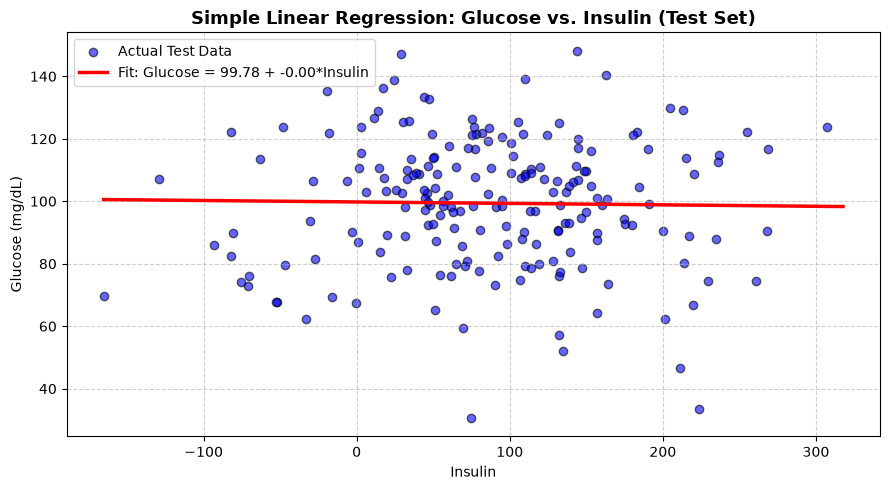

In [7]:
# Step 7: Visualization - Simple Linear Regression Line
plt.figure(figsize=(9, 5))
plt.scatter(X_test_s, y_test_s, color='blue', alpha=0.6, edgecolors='k', label='Actual Test Data')

x_vals = np.linspace(X_simple.min(), X_simple.max(), 100).reshape(-1, 1)
y_line = slr_model.predict(x_vals)
plt.plot(x_vals, y_line, color='red', linewidth=2.5, label=f'Fit: Glucose = {beta_0:.2f} + {beta_1:.2f}*Insulin')

plt.title("Simple Linear Regression: Glucose vs. Insulin (Test Set)", fontsize=13, fontweight='bold')
plt.xlabel("Insulin")
plt.ylabel("Glucose (mg/dL)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [8]:
# Step 8: Multiple Linear Regression Features & Train-Test Split
features = ['Pregnancies', 'BloodPressure', 'SkinThickness', 'Insulin', 
            'BMI', 'DiabetesPedigreeFunction', 'Age']
target = 'Glucose'

X_multi = df[features]
y_multi = df[target]

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_multi, y_multi, test_size=0.20, random_state=42
)

print(f"Multiple LR Features: {features}")
print(f"Train observations:   {X_train_m.shape[0]}")
print(f"Test observations:    {X_test_m.shape[0]}")

Multiple LR Features: ['Pregnancies', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
Train observations:   800
Test observations:    200


In [9]:
# Step 9: Fit Multiple Linear Regression Model
mlr_model = LinearRegression()
mlr_model.fit(X_train_m, y_train_m)

print(f"Intercept (beta_0): {mlr_model.intercept_:.4f}\n")
coef_df = pd.DataFrame({
    'Feature': features,
    'Coefficient': mlr_model.coef_
}).sort_values(by='Coefficient', ascending=False)
print("Learned Feature Coefficients:")
print(coef_df.to_string(index=False))

Intercept (beta_0): 93.2891

Learned Feature Coefficients:
                 Feature  Coefficient
DiabetesPedigreeFunction     4.007356
             Pregnancies     0.434316
           SkinThickness     0.291049
           BloodPressure    -0.001562
                 Insulin    -0.004100
                     Age    -0.030753
                     BMI    -0.056052


In [10]:
# Step 10: Multiple Linear Regression Evaluation
y_pred_m = mlr_model.predict(X_test_m)

mae_m = mean_absolute_error(y_test_m, y_pred_m)
mse_m = mean_squared_error(y_test_m, y_pred_m)
rmse_m = np.sqrt(mse_m)
r2_m = r2_score(y_test_m, y_pred_m)

print("=== Multiple Linear Regression Performance Metrics ===")
print(f"Mean Absolute Error (MAE):      {mae_m:.4f} mg/dL")
print(f"Mean Squared Error (MSE):       {mse_m:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse_m:.4f} mg/dL")
print(f"R-squared (R2 Score):           {r2_m:.4f}")

=== Multiple Linear Regression Performance Metrics ===
Mean Absolute Error (MAE):      16.5123 mg/dL
Mean Squared Error (MSE):       428.3464
Root Mean Squared Error (RMSE): 20.6965 mg/dL
R-squared (R2 Score):           -0.0219


In [11]:
# Step 11: Quantitative Comparison Table
comparison_df = pd.DataFrame({
    'Model': ['Simple Linear Regression (Insulin)', 'Multiple Linear Regression (7 Features)'],
    'MAE': [mae_s, mae_m],
    'MSE': [mse_s, mse_m],
    'RMSE': [rmse_s, rmse_m],
    'R2 Score': [r2_s, r2_m]
})
print("=== Model Comparison ===")
print(comparison_df.to_string(index=False))

=== Model Comparison ===
                                  Model       MAE        MSE      RMSE  R2 Score
     Simple Linear Regression (Insulin) 16.357346 419.593810 20.483989 -0.001010
Multiple Linear Regression (7 Features) 16.512261 428.346403 20.696531 -0.021891


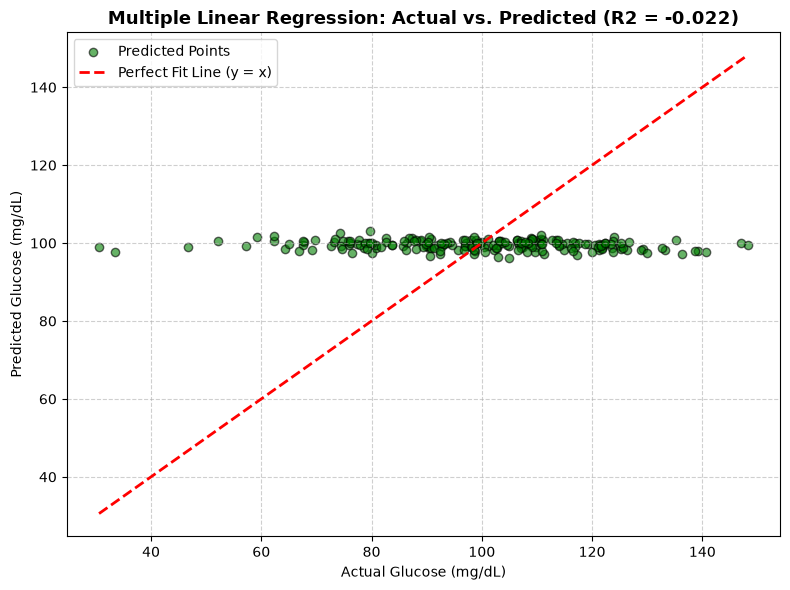

In [12]:
# Step 12: Visualization - Actual vs. Predicted (Multiple LR)
plt.figure(figsize=(8, 6))
plt.scatter(y_test_m, y_pred_m, color='green', alpha=0.6, edgecolors='k', label='Predicted Points')

min_val = min(y_test_m.min(), y_pred_m.min())
max_val = max(y_test_m.max(), y_pred_m.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Perfect Fit Line (y = x)')

plt.title(f"Multiple Linear Regression: Actual vs. Predicted (R2 = {r2_m:.3f})", fontsize=13, fontweight='bold')
plt.xlabel("Actual Glucose (mg/dL)")
plt.ylabel("Predicted Glucose (mg/dL)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

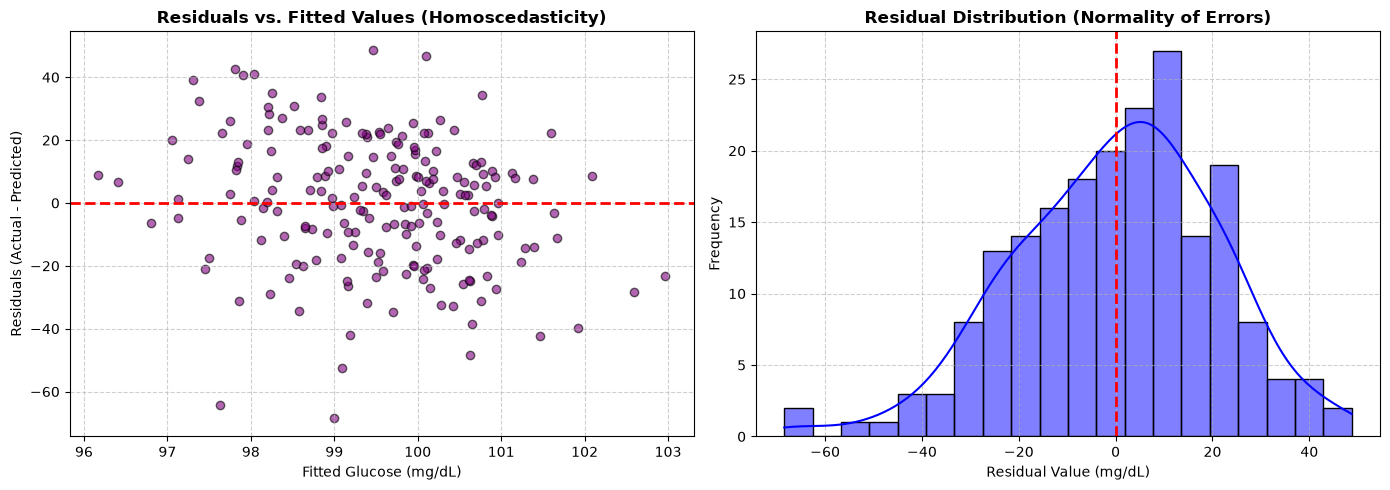

In [13]:
# Step 13: Residual Diagnostics
residuals_m = y_test_m - y_pred_m

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Residuals vs. Fitted Plot
axes[0].scatter(y_pred_m, residuals_m, color='purple', alpha=0.6, edgecolors='k')
axes[0].axhline(0, color='red', linestyle='--', linewidth=2)
axes[0].set_title("Residuals vs. Fitted Values (Homoscedasticity)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Fitted Glucose (mg/dL)")
axes[0].set_ylabel("Residuals (Actual - Predicted)")
axes[0].grid(True, linestyle='--', alpha=0.6)

# Residual Histogram
sns.histplot(residuals_m, kde=True, ax=axes[1], color='blue', bins=20)
axes[1].axvline(0, color='red', linestyle='--', linewidth=2)
axes[1].set_title("Residual Distribution (Normality of Errors)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Residual Value (mg/dL)")
axes[1].set_ylabel("Frequency")
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()